## **Reflections (week 5 - 8)**   
## **Name : Roozbeh Khodayari**

In [1]:
# import neccessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

### **Homework Reflection 5**

**1. Draw a diagram for the following negative feedback loop:**

- Sweating causes body temperature to decrease.  High body temperature causes sweating.

- A negative feedback loop means that one thing increases another while the second thing decreases the first.

- Remember that we are using directed acyclic graphs where two things cannot directly cause each other.

Because a directed acyclic graph cannot show two variables directly causing each other at the same time, I would represent the negative feedback loop across time.  

A higher body temperature at time \(t\) leads to more sweating at time \(t+1\), and more sweating at time \(t\) leads to a lower body temperature at time \(t+1\).

A simple diagram would be:

Body Temperature\(_t\) → Sweating\(_{t+1}\)  
Sweating\(_t\) → Body Temperature\(_{t+1}\)  (negative effect)

This keeps the graph acyclic while still showing the feedback loop over time.

**2. Describe an example of a positive feedback loop.  This means that one things increases another while the second things also increases the first.**

One example of a positive feedback loop is a popular social media post. When a post gets more likes, it may be shown to more people. As more people see the post, it can receive even more likes.

This creates a positive feedback loop because more likes increase the visibility of the post, and more visibility can lead to even more likes.

**3. Draw a diagram for the following situation:**

Lightning storms frighten away deer and bears, decreasing their population, and cause flowers to grow, increasing their population.
Bears eat deer, decreasing their population.
Deer eat flowers, decreasing their population.

Write a dataset that simulates this situation.  (Show the code.) Include noise / randomness in all cases.

Identify a backdoor path with one or more confounders for the relationship between deer and flowers.

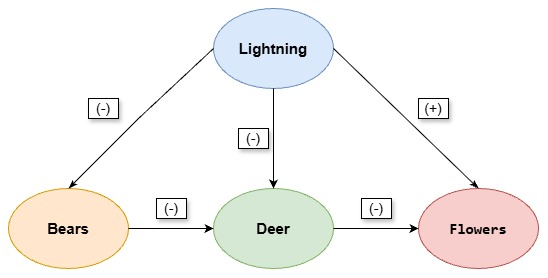

The causal diagram is shown above. Lightning storms decrease the bear and deer populations, while increasing the flower population. Bears also decrease the deer population, and deer decrease the flower population.

To simulate this situation, I created 1,000 observations. I used random values for lightning storms and added random noise when generating the bear, deer, and flower populations.

In [2]:
np.random.seed(42)
n = 1000

# 1 = lightning storm, 0 = no lightning storm
lightning = np.random.binomial(1, 0.3, n)

# Lightning decreases bears
bears = 50 - 15 * lightning + np.random.normal(0, 5, n)

# Lightning and bears decrease deer
deer = (100- 20 * lightning- 0.5 * bears+ np.random.normal(0, 10, n))

# Lightning increases flowers, while deer decrease flowers
flowers = (200+ 30 * lightning- 0.8 * deer+ np.random.normal(0, 15, n))

# Prevent negative population values
bears = np.maximum(bears, 0)
deer = np.maximum(deer, 0)
flowers = np.maximum(flowers, 0)

df = pd.DataFrame({"Lightning": lightning,"Bears": bears,"Deer": deer,"Flowers": flowers})

df.head()

,Lightning,Bears,Deer,Flowers
0,0,50.888505,60.492573,164.723698
1,1,28.323278,65.007305,168.247677
2,1,36.900989,46.502302,174.750146
3,0,53.052929,81.074095,119.510058
4,0,52.798952,74.424921,133.152019


For the relationship between deer and flowers, one backdoor path is:

**Deer ← Lightning → Flowers**

Lightning is a confounder because it affects both the deer population and the flower population. Another backdoor path is **Deer ← Bears ← Lightning → Flowers**.

**4. Draw a diagram for a situation of your own invention.  The diagram should include at least four nodes, one confounder, and one collider.**  

Be sure that it is acyclic (no loops).  Which node would say is most like a treatment (X)?  Which is most like an outcome (Y)?

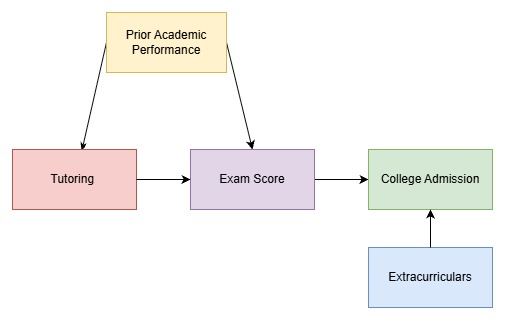

In this example, I am looking at the effect of **Tutoring** on **Exam Score**. I would consider **Tutoring** to be the treatment (X) and **Exam Score** to be the outcome (Y).

**Prior Academic Performance** is a confounder because it can affect both whether a student receives tutoring and how well the student performs on the exam. This creates the path:

**Tutoring ← Prior Academic Performance → Exam Score**

**College Admission** is a collider because it is affected by both **Exam Score** and **Extracurriculars**. This creates the path:

**Exam Score → College Admission ← Extracurriculars**

The diagram is acyclic because the arrows move in one direction and do not form any loop.

### **Homework Reflection 6**

**1. What is a potential problem with computing the Marginal Treatment Effect simply by comparing each untreated item to its counterfactual and taking the maximum difference?**   

(Hint: think of statistics here.  Consider that only the most extreme item ends up being used to estimate the MTE.  That's not necessarily a bad thing; the MTE is supposed to come from the untreated item that will produce the maximum effect.  But there is nevertheless a problem.)
Possible answer: We are likely to find the item with the most extreme difference, which may be high simply due to randomness.
(Please explain / justify this answer, or give a different one if you can think of one.)

A potential problem is that the maximum difference may be extreme partly because of random variation in the data.  

Since we compare many untreated items and only keep the largest effect, we are more likely to select an unusually high value by chance.   

This could make the estimated MTE larger than the true effect and less stable across different samples.

**2. Propose a solution that remedies this problem and write some code that implements your solution.  It's very important here that you clearly explain what your solution will do.** 

Possible answer: maybe we could take the 90th percentile of the treatment effect and use it as a proxy for the Marginal Treatment Effect. (Either code this answer or choose a different one.)

**Primary solution: 90th percentile**  

One possible solution is to use the 90th percentile of the estimated treatment effects instead of using the single maximum value.  

The maximum can be unusually high just because of random variation in one observation.  

The 90th percentile still represents a relatively large treatment effect, but it is less dependent on one extreme value.  

Therefore, I would use the 90th percentile as a proxy for the Marginal Treatment Effect.


In [3]:
import pandas as pd
import numpy as np
from sklearn.neighbors import NearestNeighbors

# Load the data
df = pd.read_csv("../data/homework_6.1.csv")

# Separate treated and untreated items
treated = df[df["X"] == 1]
untreated = df[df["X"] == 0]

# Find the nearest treated match for each untreated item using Z
nn = NearestNeighbors(n_neighbors=1)
nn.fit(treated[["Z"]])

_, idx = nn.kneighbors(untreated[["Z"]])

# Estimate the treatment effect for each untreated item
untreated_effects = (treated.iloc[idx.flatten()]["Y"].to_numpy()- untreated["Y"].to_numpy())

# Use the 90th percentile instead of the maximum
mte_proxy = np.percentile(untreated_effects, 90)

print("90th percentile estimate:", mte_proxy)

90th percentile estimate: 1.9279622855613059


**Additional stability check: Bootstrap resampling**  

I would also use bootstrap resampling as a stability check.  

After estimating the treatment effect for each untreated item, I would repeatedly resample these effects with replacement and calculate the 90th percentile for each bootstrap sample.  

If the bootstrap estimates are fairly similar, this gives more confidence that the result is not being driven by one unusual observation.  

The bootstrap does not completely remove the uncertainty, but it helps show how stable the estimate is across different samples.

In [4]:
# Bootstrap the 90th percentile to check its stability
bootstrap_estimates = []

for _ in range(1000):
    sample = np.random.choice(untreated_effects,size=len(untreated_effects),replace=True)

    bootstrap_estimates.append(np.percentile(sample, 90))

bootstrap_estimate = np.mean(bootstrap_estimates)

print("Average bootstrap estimate:", bootstrap_estimate)
print("Bootstrap standard deviation:", np.std(bootstrap_estimates))

Average bootstrap estimate: 1.9268481531050448
Bootstrap standard deviation: 0.017005415589348708


### **Homework Reflection 7**


**1. Create a linear regression model involving a confounder that is left out of the model.  Show whether the true correlation between X and Y is overestimated, underestimated, or neither.**   

Explain in words why this is the case for the given coefficients you have chosen.

**2. Perform a linear regression analysis in which one of the coefficients is zero, e.g.**

W = [noise]  
X = [noise]  
Y = 2 * X + [noise]

And compute the p-value of a coefficient - in this case, the coefficient of W.  
(This is the likelihood that the estimated coefficient would be as high or low as it is, given that the actual coefficient is zero.)
If the p-value is less than 0.05, this ordinarily means that we judge the coefficient to be nonzero (incorrectly, in this case.)
Run the analysis 1000 times and report the best (smallest) p-value.  
If the p-value is less than 0.05, does this mean the coefficient actually is nonzero?  What is the problem with repeating the analysis?

### **Homework Reflection 8**


Include the code you used to solve Week 8's coding quiz problems and write about the obstacles / challenges / insights you encountered while solving them.